# How to locate a buggy sub with subwise counting

## The problem

When a large FTQC circuit uses more T gates, more ancillas, or more Toffolis than you expected, the aggregate count from `GateCountEvaluatorHooks` tells you *that* something is off but not *where*. The usual workaround is to chop the circuit into pieces by hand, compile each piece, and count each piece in isolation until the offending sub shows up.

Subwise counting removes that detour. It walks the compiled `MachineSub` once and reports, per `Sub`:

- how many times the sub is called from the upper-level sub,
- how many qubtis are required the sub (input/output plus auxiliary qubits used inside it),
- a breakdown of the primitive gates contained directly in that sub.

With that report in hand, the sub whose numbers do not match your manually calculated expectation is the sub to inspect.

This guide walks through that workflow end to end:

1. Build a small circuit composed of several custom subs, one of which has a bug.
2. Try to find the bug with aggregate counts and watch it fail.
3. Run subwise counting, read the report, and pinpoint the bad sub.
4. Fix the sub and confirm with subwise counting again.

## Step 1. Build a circuit with nested subs

We will build a tiny arithmetic-style circuit out of three custom subs:

- `HalfAdder` — expected to be cheap.
- `Comparator` — expected to be moderately expensive.
- `Pipeline` — top-level sub that calls both several times.

One of them (`HalfAdder`) intentionally has a bug: it controls an extra rotation that has no business being there, inflating its T count.


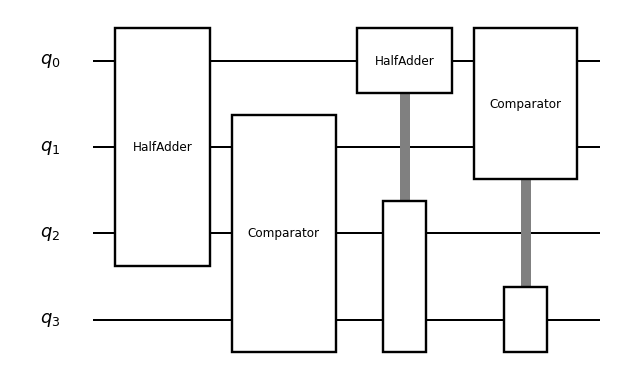

In [70]:
from quri_parts.qsub.opsub import UnitarySubDef, opsub
from quri_parts.qsub.sub import SubBuilder
from quri_parts.qsub.lib import std
from quri_parts.qsub.visualize import draw

# TODO: implement exponentially scaling bug while expecting linear scaling.


class HalfAdderDef(UnitarySubDef):
    name = "HalfAdder"
    qubit_count = 3

    def sub(self, b: SubBuilder) -> None:
        a, x, y = b.qubits
        b.add_op(std.Toffoli, (a, x, y))
        b.add_op(std.CNOT, (a, x))
        # Bug: this multi-controlled S has no reason to be here.
        # It is the kind of leftover that aggregate counts will not surface.
        b.add_op(std.MultiControlled(std.S, 2, 0b11), (a, x, y))


HalfAdder, _ = opsub(HalfAdderDef)


# greater-than comparator for 1-bit unsigned integers, i.e. it flips y iff a > x.
class ComparatorDef(UnitarySubDef):
    name = "Comparator"
    qubit_count = 3

    def sub(self, b: SubBuilder) -> None:
        a, x, y = b.qubits
        # Flip y iff a == 1 and x == 0  (i.e. a > x as 1-bit unsigned ints).
        b.add_op(std.X, (x,))
        b.add_op(std.Toffoli, (a, x, y))
        b.add_op(std.X, (x,))


Comparator, _ = opsub(ComparatorDef)


class PipelineDef(UnitarySubDef):
    name = "Pipeline"
    qubit_count = 4

    def sub(self, b: SubBuilder) -> None:
        q0, q1, q2, q3 = b.qubits
        b.add_op(HalfAdder, (q0, q1, q2))
        b.add_op(Comparator, (q1, q2, q3))
        b.add_op(HalfAdder, (q0, q2, q3))
        b.add_op(Comparator, (q0, q1, q3))


Pipeline, _ = opsub(PipelineDef)
draw(Pipeline)

In [71]:
from quri_parts.qsub.compile import compile

primitives = (std.X, std.H, std.T, std.Tdag, std.S, std.Sdag, std.CNOT, std.Toffoli)
compiled = compile(Pipeline, primitives)

## Step 2. Why aggregate counting is not enough

Run the existing `GateCountEvaluatorHooks` first. The numbers will look high, but the report does not say which sub is responsible.

In [72]:
from quri_parts.qsub.evaluate import Evaluator
from quri_parts.qsub.eval import GateCountEvaluatorHooks

totals = Evaluator(GateCountEvaluatorHooks((std.T, std.Tdag, std.CNOT, std.Toffoli))).run(compiled)
print({k[1]: v for k, v in totals.items()})

{'Toffoli': 8, 'CNOT': 6, 'Tdag': 2, 'T': 4}


Suppose the T count is much larger than you expected. From this dict alone you cannot tell whether `HalfAdder`, `Comparator`, or the framework's `MultiControlled` resolution is the source. Up to now the only way forward has been to recompile each sub in isolation. Subwise counting replaces that loop.

## Step 3. Run subwise counting

`SubwiseCountEvaluatorHooks` is the new hook. Its API mirrors `GateCountEvaluatorHooks` so it slots into the same `Evaluator` pipeline:

- Constructor takes the gates you want broken down. Pass nothing to count *every* primitive that appears.
- `run(compiled)` returns a `SubwiseCountReport` keyed by **`base_id`**, so two subs that happen to share a `name` cannot collide.
- Each entry exposes:
  - `name`, `base_id` — readable name plus the unique identity used as the key.
  - `calls` — how many times this sub is invoked across the program.
  - `data_qubits`, `aux_qubits` — input/output width and auxiliary qubits allocated inside the sub, reported as two separate numbers.

  TODO:
  - `gates_self` — gates contained *directly* in this sub, per single invocation.
  - `gates_subtree` — same, rolled up across every sub this one calls into, per single invocation.

`pretty()` prints both `base_id` and `name`, and shows `self` and `subtree` gate columns side by side so the source and the rolled-up cost are visible at once.

In [ ]:
from quri_parts.qsub.eval import SubwiseCountEvaluatorHooks

hooks = SubwiseCountEvaluatorHooks(gates=(std.T, std.Tdag, std.CNOT, std.Toffoli))
report_data = Evaluator(hooks).run(compiled)

In [94]:
import pandas as pd

# this is dummy data as SubwiseCountEvaluatorHooks is not implemented yet.
report_data = [
    {
        "name": "Pipeline",
        "call_count": 1,
        "qubit_count_info": {"auxiliary": 0, "data": 4, "total": 4},
        "gate_count_info": {
            "self_per_call": {},
            "self": {},
            "descendants_per_call": {"T": 4, "Tdag": 2, "CNOT": 6, "Toffoli": 8},
            "descendants": {"T": 4, "Tdag": 2, "CNOT": 6, "Toffoli": 8},
            "total_per_call": {"T": 4, "Tdag": 2, "CNOT": 6, "Toffoli": 8},
            "total": {"T": 4, "Tdag": 2, "CNOT": 6, "Toffoli": 8},
        },
    },
    {
        "name": "HalfAdder",
        "call_count": 2,
        "qubit_count_info": {"auxiliary": 0, "data": 3, "total": 3},
        "gate_count_info": {
            "self_per_call": {"T": 2, "Tdag": 1, "CNOT": 3, "Toffoli": 3},
            "self": {"T": 4, "Tdag": 2, "CNOT": 6, "Toffoli": 6},
            "descendants_per_call": {},
            "descendants": {},
            "total_per_call": {"T": 2, "Tdag": 1, "CNOT": 3, "Toffoli": 3},
            "total": {"T": 4, "Tdag": 2, "CNOT": 6, "Toffoli": 6},
        },
    },
    {
        "name": "Comparator",
        "call_count": 2,
        "qubit_count_info": {"auxiliary": 0, "data": 3, "total": 3},
        "gate_count_info": {
            "self_per_call": {"Toffoli": 1},
            "self": {"Toffoli": 2},
            "descendants_per_call": {},
            "descendants": {},
            "total_per_call": {"Toffoli": 1},
            "total": {"Toffoli": 2},
        },
    },
    { "name": "multi-controlled S" },
]

# cprofiler:
# analogyを探す

pd.set_option('display.max_colwidth', None)
df = pd.DataFrame(report_data)
df

,name,call_count,qubit_count_info,gate_count_info
0,Pipeline,1.0,"{'auxiliary': 0, 'data': 4, 'total': 4}","{'self': {}, 'self_all_call': {}, 'descendants': {'T': 4, 'Tdag': 2, 'CNOT': 6, 'Toffoli': 8}, 'descendants_all_call': {'T': 4, 'Tdag': 2, 'CNOT': 6, 'Toffoli': 8}, 'total': {'T': 4, 'Tdag': 2, 'CNOT': 6, 'Toffoli': 8}}"
1,HalfAdder,2.0,"{'auxiliary': 0, 'data': 3, 'total': 3}","{'self': {'T': 2, 'Tdag': 1, 'CNOT': 3, 'Toffoli': 3}, 'descendants': {}, 'total': {'T': 2, 'Tdag': 1, 'CNOT': 3, 'Toffoli': 3}}"
2,Comparator,2.0,"{'auxiliary': 0, 'data': 3, 'total': 3}","{'self': {'Toffoli': 1}, 'descendants': {}, 'total': {'Toffoli': 1}}"
3,multi-controlled S,NaN,NaN,NaN


In [93]:
normalized = pd.json_normalize(report_data)
normalized[["name", "call_count", *[col for col in normalized.columns if col.startswith("gate_count_info.self")],]]

,name,call_count,gate_count_info.self.T,gate_count_info.self.Tdag,gate_count_info.self.CNOT,gate_count_info.self.Toffoli
0,Pipeline,1.0,NaN,NaN,NaN,NaN
1,HalfAdder,2.0,2.0,1.0,3.0,3.0
2,Comparator,2.0,NaN,NaN,NaN,1.0
3,multi-controlled S,NaN,NaN,NaN,NaN,NaN


Two things jump out:

TODO:

1. `HalfAdder`'s `direct` column already shows 2 `T` per call. Because `direct` column only counts what is *directly inside* the sub, those T gates can only be coming from a primitive sequence written into `HalfAdder` itself.

## Step 4. Zoom in on the offending sub

If you want everything inside one sub (not just the gates you preselected), ask the report for it directly.

In [ ]:
halfadder_entry = report.for_sub(HalfAdder.base_id)
print(halfadder_entry.name, halfadder_entry.base_id)
print("calls:", halfadder_entry.calls)
print("data qubits:", halfadder_entry.data_qubits, " aux qubits:", halfadder_entry.aux_qubits)
print("gates (this sub only, per call):", halfadder_entry.gates_self)
print("gates (including everything it calls, per call):", halfadder_entry.gates_subtree)

Because `gates_self` and `gates_subtree` for `HalfAdder` are equal, the cost is *not* coming from any sub it calls — it is in the body of `HalfAdder` itself. That narrows the search to a single source file and confirms the stray `MultiControlled(S, ...)` is the culprit before reading any code.

## Step 5. Fix and re-check

Remove the stray `MultiControlled` from `HalfAdder` and rerun subwise counting. The expectation is that the T column for `HalfAdder` drops to zero and total T from Step 2 falls accordingly.

{'Toffoli': 2, 'CNOT': 2, 'Tdag': 1, 'T': 2}


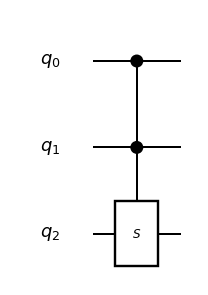

In [89]:
from quri_parts.qsub.visualize import draw_msub


class HalfAdderDef(UnitarySubDef):  # noqa: F811 — replacing the buggy definition
    name = "HalfAdder"
    qubit_count = 3

    def sub(self, b: SubBuilder) -> None:
        a, x, y = b.qubits
        b.add_op(std.Toffoli, (a, x, y))
        b.add_op(std.CNOT, (a, x))


HalfAdder, _ = opsub(HalfAdderDef)

compiled = compile(Pipeline, primitives)
compiled = compile(HalfAdder, primitives)

totals = Evaluator(GateCountEvaluatorHooks(primitives)).run(compiled)
print({k[1]: v for k, v in totals.items()})
# report = Evaluator(SubwiseCountEvaluatorHooks(gates=(std.T, std.Tdag, std.CNOT, std.Toffoli))).run(compiled)
# print(report.pretty())
draw_msub(compiled)